# Hotel Harmony: Hotel Booking EDA


**Data:** [Hotel booking demand](https://www.kaggle.com/jessemostipak/hotel-booking-demand) (Kaggle), 119,390 bookings, 32 columns, arrivals from July 2015 to August 2017.

**How this notebook is organised:** 1) load and clean, 2) basic questions, 3) medium questions, 4) advanced questions, 5) summary. After each question I write what I found in plain words.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import classification_report, confusion_matrix, r2_score, mean_absolute_error

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

## 1. Load and clean the data

In [2]:
raw = pd.read_csv('../data/hotel_bookings.csv')
print(raw.shape)
raw.head(3)

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


In [3]:
# which columns have missing values?
raw.isnull().sum()[lambda s: s > 0]

children         4
country        488
agent        16340
company     112593
dtype: int64

`company` is 94% empty and `agent` is 14% empty. I think a blank here just means *no company / no agent was involved*, so I fill them with 0 instead of dropping rows. `children` (4 rows) gets 0 and `country` gets 'Unknown'.

In [4]:
print('duplicate rows:', raw.duplicated().sum())
print('share of data:', round(raw.duplicated().mean()*100, 1), '%')

duplicate rows: 31994
share of data: 26.8 %


About 27% of rows are exact duplicates. There is no booking ID, so I can't be 100% sure they are all true duplicates (two identical rooms booked together would look the same). I decided to **remove them** so a stay isn't counted twice. This matters: it changes the cancellation rate from 37% to 27.5%.

In [5]:
df = raw.drop_duplicates().copy()
df['children'] = df['children'].fillna(0)
df['country']  = df['country'].fillna('Unknown')
df['agent']    = df['agent'].fillna(0)
df['company']  = df['company'].fillna(0)

months = ['January','February','March','April','May','June','July',
          'August','September','October','November','December']
month_num = {m: i+1 for i, m in enumerate(months)}
df['arrival_date'] = pd.to_datetime(dict(year=df.arrival_date_year,
                                         month=df.arrival_date_month.map(month_num),
                                         day=df.arrival_date_day_of_month))
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# new columns I will use later
df['total_nights'] = df.stays_in_weekend_nights + df.stays_in_week_nights
df['estimated_revenue'] = df.adr * df.total_nights
df['guest_type'] = np.where(df.is_repeated_guest == 1, 'Repeated', 'New')
season_map = {'December':'Winter','January':'Winter','February':'Winter',
              'March':'Spring','April':'Spring','May':'Spring',
              'June':'Summer','July':'Summer','August':'Summer',
              'September':'Autumn','October':'Autumn','November':'Autumn'}
df['season'] = df.arrival_date_month.map(season_map)

print('rows after cleaning:', len(df))

rows after cleaning: 87396


**Two things I noticed but did not fix:**
- 1,778 bookings have an ADR of 0 (many look like free/complimentary stays) and one has an ADR of 5,400. These pull averages a bit.
- The data starts in July 2015 and ends in August 2017, so July and August appear 3 times and other months only 2 times. I keep this in mind when comparing months.

## 2. Basic questions

**Q1. Average lead time**

In [6]:
print('mean  :', round(df.lead_time.mean(), 1), 'days')
print('median:', df.lead_time.median(), 'days')

mean  : 79.9 days
median: 49.0 days


Guests book about 80 days ahead on average, but the median is 49. A few very early bookers pull the average up.

**Q2. Bookings by hotel type**

hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64


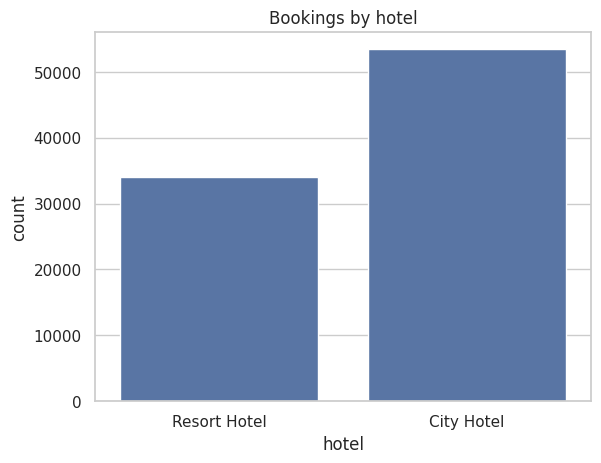

In [7]:
print(df.hotel.value_counts())
sns.countplot(data=df, x='hotel'); plt.title('Bookings by hotel'); plt.show()

City Hotel has 53,428 bookings (61%) and Resort Hotel has 33,968 (39%).

**Q3. How many bookings were cancelled?**

In [8]:
print(df.is_canceled.sum(), 'cancelled')
print(round(df.is_canceled.mean()*100, 1), '% of all bookings')

24025 cancelled
27.5 % of all bookings


24,025 bookings were cancelled, which is 27.5%. More than 1 in 4 bookings never turns into a stay.

**Q4. Most common arrival month**

arrival_date_month
August    11257
July      10057
May        8355
Name: count, dtype: int64


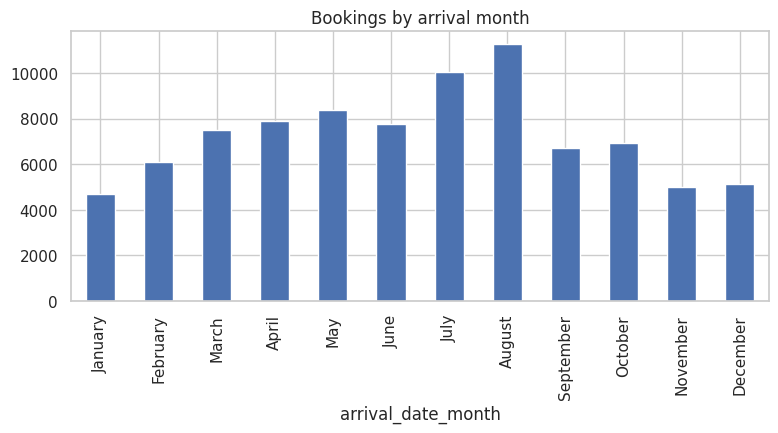

In [9]:
counts = df.arrival_date_month.value_counts().reindex(months)
print(counts.sort_values(ascending=False).head(3))
counts.plot(kind='bar', figsize=(9,3.5), title='Bookings by arrival month'); plt.show()

August is the busiest month (11,257 bookings), then July and May. Because July and August have 3 years of data, their totals look bigger than they would for a fair comparison, but August still wins on revenue later (Q17).

**Q5. Average special requests per booking**

In [10]:
print(round(df.total_of_special_requests.mean(), 2))
print((df.total_of_special_requests == 0).mean().round(3))

0.7
0.502


0.70 requests per booking. Half of all bookings make no request at all.

**Q6. Country with the most bookings**

In [11]:
df.country.value_counts().head(6)

country
PRT    27453
GBR    10433
FRA     8837
ESP     7252
DEU     5387
ITA     3066
Name: count, dtype: int64

Portugal (PRT) is first with 27,453 bookings (31%), then Great Britain, France, Spain and Germany.

**Q7. Average ADR by hotel**

In [12]:
df.groupby('hotel').adr.mean().round(2)

hotel
City Hotel      110.99
Resort Hotel     99.03
Name: adr, dtype: float64

City Hotel earns about 111 per night and Resort Hotel about 99.

**Q8. % of bookings that needed parking**

In [13]:
print(round((df.required_car_parking_spaces > 0).mean()*100, 1), '%')
df.groupby('hotel').required_car_parking_spaces.apply(lambda s: round((s>0).mean()*100,1))

8.4 %


hotel
City Hotel       3.5
Resort Hotel    15.9
Name: required_car_parking_spaces, dtype: float64

8.4% overall, but it is very different by hotel: 15.9% at the Resort versus 3.5% in the City Hotel.

**Q9. Average stay (weekday vs weekend nights)**

In [14]:
df[['stays_in_week_nights','stays_in_weekend_nights','total_nights']].mean().round(2)

stays_in_week_nights       2.63
stays_in_weekend_nights    1.01
total_nights               3.63
dtype: float64

About 2.6 week nights and 1.0 weekend night, so 3.6 nights in total. Resort guests stay longer (4.4 nights) than City guests (3.1).

**Q10. Bookings made through travel agents**

In [15]:
print((df.agent != 0).sum(), 'bookings')
print(round((df.agent != 0).mean()*100, 1), '%')

75203 bookings
86.0 %


75,203 bookings (86%) involved a travel agent. Agents matter a lot to this business.

## 3. Medium questions

**Q11. Cancellation rate by hotel**

hotel
City Hotel      30.0
Resort Hotel    23.5
Name: is_canceled, dtype: float64


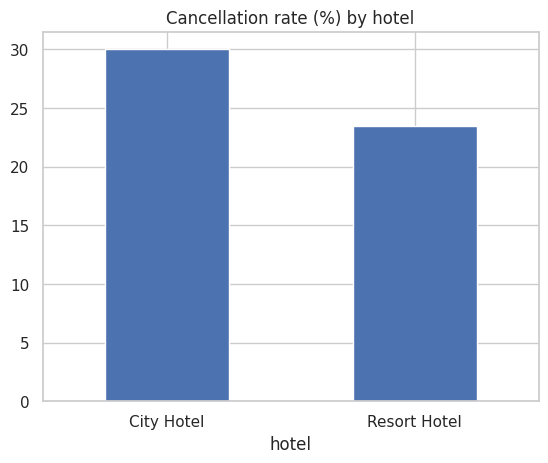

In [16]:
rate = (df.groupby('hotel').is_canceled.mean()*100).round(1)
print(rate)
rate.plot(kind='bar', rot=0, title='Cancellation rate (%) by hotel'); plt.show()

City Hotel: 30.0%, Resort Hotel: 23.5%. The city hotel loses more bookings.

**Q12. Average ADR by market segment**

market_segment
Complementary      3.0
Undefined         15.0
Corporate         68.2
Groups            74.9
Offline TA/TO     81.8
Aviation         100.2
Direct           116.6
Online TA        118.2
Name: adr, dtype: float64


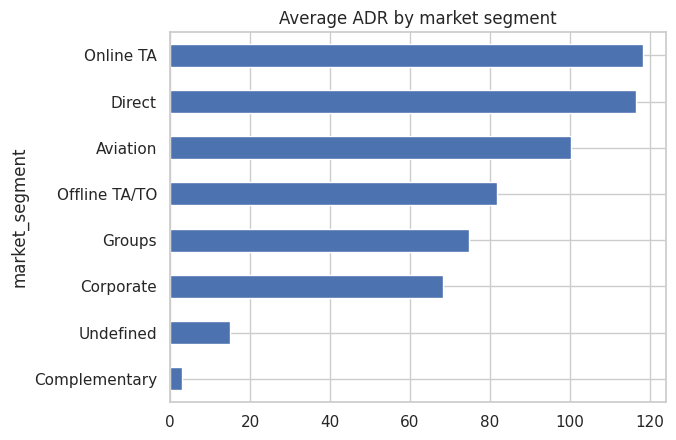

In [17]:
adr_seg = df.groupby('market_segment').adr.mean().sort_values()
print(adr_seg.round(1))
adr_seg.plot(kind='barh', title='Average ADR by market segment'); plt.show()

Online TA (118) and Direct (117) have the highest rates. Corporate (68) and Groups (75) pay less. 'Complementary' is about 3 because those stays are free, so I ignore it when comparing.

**Q13. Lead time vs cancellation**

lead_band
0-7         8.4
8-30       25.4
31-60      31.6
61-90      32.6
91-180     35.0
181-365    39.7
365+       40.9
Name: is_canceled, dtype: float64


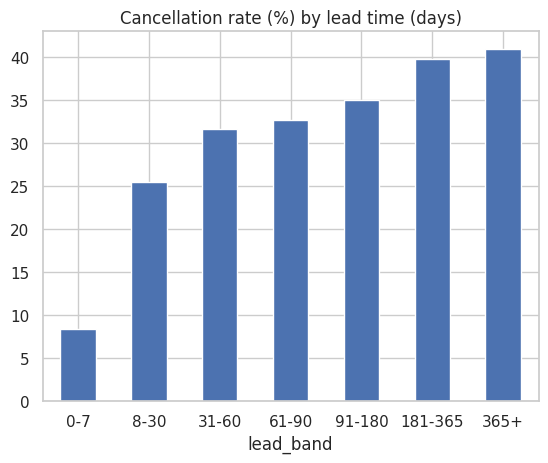

correlation: 0.18


In [18]:
# a scatter plot of a 0/1 column is hard to read, so I group lead time into bands
df['lead_band'] = pd.cut(df.lead_time, [-1,7,30,60,90,180,365,np.inf],
    labels=['0-7','8-30','31-60','61-90','91-180','181-365','365+'])
band = (df.groupby('lead_band', observed=True).is_canceled.mean()*100).round(1)
print(band)
band.plot(kind='bar', rot=0, title='Cancellation rate (%) by lead time (days)'); plt.show()
print('correlation:', df[['lead_time','is_canceled']].corr().iloc[0,1].round(2))

The earlier someone books, the more likely they cancel: 8% when booked within a week, around 40% when booked a year or more ahead. The overall correlation is only 0.18, which looks weak, but the bands show the pattern clearly.

**Q14. Distribution channel with the most bookings**

In [19]:
df.distribution_channel.value_counts()

distribution_channel
TA/TO        69141
Direct       12988
Corporate     5081
GDS            181
Undefined        5
Name: count, dtype: int64

TA/TO (travel agents and tour operators) brings 69,141 bookings, about 79%. That is a lot of dependence on one channel.

**Q15. Previous cancellations by hotel**

In [20]:
df.groupby('hotel').previous_cancellations.mean().round(3)

hotel
City Hotel      0.036
Resort Hotel    0.022
Name: previous_cancellations, dtype: float64

Both are tiny (0.036 and 0.022) because only about 2% of bookings have a cancellation in their past. City Hotel is a bit higher, which fits with its higher cancellation rate.

**Q16. ADR trend over the years**

arrival_date_year
2015     92.2
2016    101.5
2017    118.7
Name: adr, dtype: float64


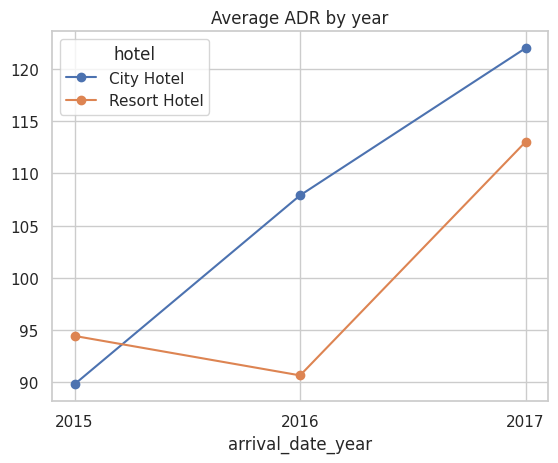

In [21]:
print(df.groupby('arrival_date_year').adr.mean().round(1))
df.groupby(['arrival_date_year','hotel']).adr.mean().unstack().plot(marker='o', title='Average ADR by year')
plt.xticks([2015,2016,2017]); plt.show()

ADR goes from 92 (2015) to 102 (2016) to 119 (2017). One caution: 2015 only has July to December and 2017 only January to August, and summer rates are higher, so part of this rise is from the months included. I would need to compare the same months to be sure.

**Q17. Month with the highest revenue**

arrival_date_month
January      0.71
February     1.03
March        1.42
April        1.81
May          2.06
June         2.30
July         3.80
August       4.61
September    1.97
October      1.48
November     0.89
December     0.92
Name: estimated_revenue, dtype: float64


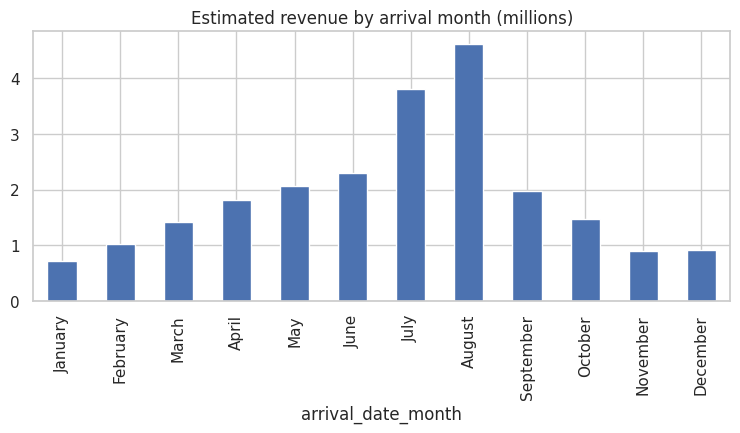

In [22]:
# the brief suggests summing ADR, but ADR is a per-night rate, so I use ADR x nights.
# I also count only stays that were not cancelled.
rev = (df[df.is_canceled == 0].groupby('arrival_date_month').estimated_revenue.sum()
       .reindex(months) / 1e6).round(2)
print(rev)
rev.plot(kind='bar', figsize=(9,3.5), title='Estimated revenue by arrival month (millions)'); plt.show()

August is the highest-revenue month, and July is second. This is true with every method I tried (sum of ADR, ADR x nights, with and without cancelled bookings).

**Q18. Special requests vs ADR**

In [23]:
print(df.groupby('total_of_special_requests').adr.mean().round(1))
print('correlation:', df[['total_of_special_requests','adr']].corr().iloc[0,1].round(2))

total_of_special_requests
0     99.7
1    109.7
2    118.6
3    125.1
4    131.1
5    130.0
Name: adr, dtype: float64
correlation: 0.14


ADR goes up with the number of requests (100 with none, 131 with four). The correlation is only 0.14. This doesn't prove requests *cause* higher prices. Guests who pay more may just ask for more.

**Q19. Stay length: repeated vs new guests**

In [24]:
df.groupby('guest_type').total_nights.mean().round(2)

guest_type
New         3.70
Repeated    1.93
Name: total_nights, dtype: float64

Repeated guests stay 1.9 nights, new guests 3.7. They are also only 3.9% of all bookings.

**Q20. Most booked room type**

In [25]:
df.reserved_room_type.value_counts(normalize=True).head(4).mul(100).round(1)

reserved_room_type
A    64.7
D    19.9
E     6.9
F     3.2
Name: proportion, dtype: float64

Room type A is by far the most booked (about 65%).

## 4. Advanced questions

**Q21. What drives cancellations? (logistic regression)**

              precision    recall  f1-score   support

           0       0.75      0.96      0.84     12675
           1       0.63      0.16      0.25      4805

    accuracy                           0.74     17480
   macro avg       0.69      0.56      0.55     17480
weighted avg       0.72      0.74      0.68     17480

[[12220   455]
 [ 4038   767]]


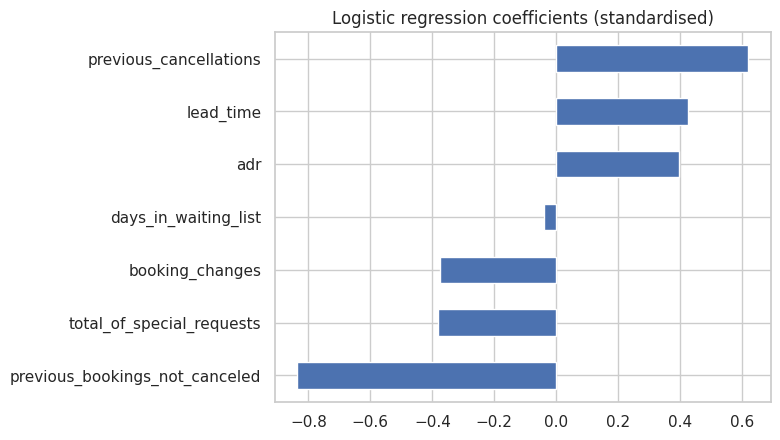

In [26]:
features = ['lead_time','previous_cancellations','previous_bookings_not_canceled',
            'booking_changes','days_in_waiting_list','adr','total_of_special_requests']
X, y = df[features], df.is_canceled
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_tr)
model = LogisticRegression(max_iter=1000).fit(scaler.transform(X_tr), y_tr)
pred = model.predict(scaler.transform(X_te))

print(classification_report(y_te, pred))
print(confusion_matrix(y_te, pred))
coefs = pd.Series(model.coef_[0], index=features).sort_values()
coefs.plot(kind='barh', title='Logistic regression coefficients (standardised)'); plt.show()

**What I found:**
- Guests with more *completed* past stays cancel much less. Guests with *past cancellations* cancel much more.
- Longer lead time and higher ADR go with more cancellations. Special requests and booking changes go with fewer.
- The model is 74% accurate, but 72.5% of bookings are not cancelled, so a model that always says "not cancelled" would score almost the same. It only finds 16% of real cancellations. **So it is good for understanding drivers, not for predicting.** To improve it I want to try class weights and a random forest.

In [27]:
# one extra check: deposit type
print((df.groupby('deposit_type').is_canceled.mean()*100).round(1))
print(df.deposit_type.value_counts())

deposit_type
No Deposit    26.7
Non Refund    94.7
Refundable    24.3
Name: is_canceled, dtype: float64
deposit_type
No Deposit    86251
Non Refund     1038
Refundable      107
Name: count, dtype: int64


Strange result: 'Non Refund' bookings are cancelled 94.7% of the time (only 1,038 bookings). That is the opposite of what I'd expect, so I think there is a data or process issue. I'd ask the hotel what 'Non Refund' means in their system before using it.

**Q22. How does ADR change with adults, children and babies? (linear regression)**

In [28]:
Xa, ya = df[['adults','children','babies']], df.adr
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2, random_state=42)
lin = LinearRegression().fit(Xa_tr, ya_tr)
print(dict(zip(Xa.columns, lin.coef_.round(1))), 'intercept', round(lin.intercept_, 1))
p = lin.predict(Xa_te)
print('R2:', round(r2_score(ya_te, p), 2), ' MAE:', round(mean_absolute_error(ya_te, p), 1))

{'adults': np.float64(20.0), 'children': np.float64(38.4), 'babies': np.float64(6.9)} intercept 63.2
R2: 0.2  MAE: 35.6


Each extra child adds about 38 to the nightly rate, each extra adult about 20, and a baby about 7. But R² is only 0.20, so guest count explains just a fifth of the price. Season, hotel and room type probably matter more.

**Q23. Booking changes vs special requests**

In [29]:
cols = ['booking_changes','total_of_special_requests']
print(df[cols].corr().iloc[0,1].round(3))
print((df.assign(bc=df.booking_changes.clip(upper=4)).groupby('bc').is_canceled.mean()*100).round(1))

0.016
bc
0    30.2
1    13.9
2    20.1
3    15.0
4    18.0
Name: is_canceled, dtype: float64


There is almost no relationship (correlation 0.016). Also, special requests aren't really a measure of satisfaction, and this dataset has no satisfaction score, so I can't answer the question as written. A side finding: guests who change their booking cancel *less* (14% with one change vs 30% with none).

**Q24. Seasonal impact on cancellations**

season
Autumn    23.3
Spring    28.1
Summer    31.6
Winter    24.1
Name: is_canceled, dtype: float64


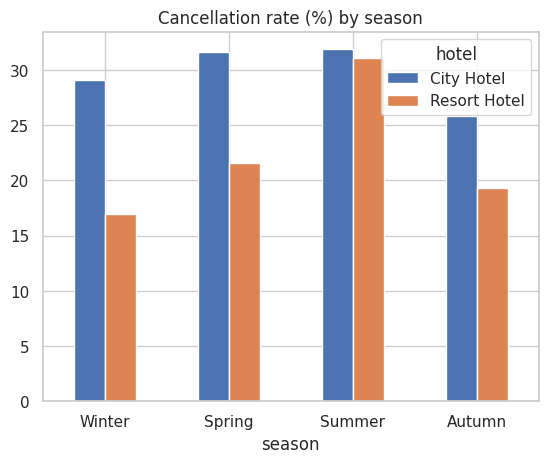

In [30]:
print((df.groupby('season').is_canceled.mean()*100).round(1))
(df.groupby(['season','hotel']).is_canceled.mean().unstack()*100).reindex(
    ['Winter','Spring','Summer','Autumn']).plot(kind='bar', rot=0, title='Cancellation rate (%) by season'); plt.show()

Summer has the highest cancellations (31.6%) and autumn the lowest (23.3%). The Resort changes a lot by season (31% in summer, 17% in winter) while the City Hotel stays high all year.

**Q25. Lead time by market segment**

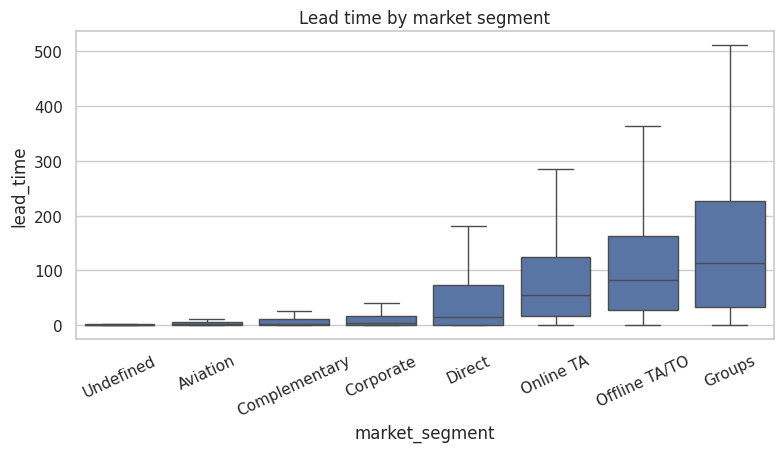

In [31]:
order = df.groupby('market_segment').lead_time.median().sort_values().index
plt.figure(figsize=(9,4))
sns.boxplot(data=df, x='market_segment', y='lead_time', order=order, showfliers=False)
plt.xticks(rotation=25); plt.title('Lead time by market segment'); plt.show()

Groups plan far ahead (median 114 days), then offline agents (82) and online agents (55). Direct (15), Corporate (5) and Aviation (3) book very late.

## 5. Summary

| What I found | Why it matters |
|---|---|
| 27.5% of bookings are cancelled; City Hotel 30%, Resort 23.5% | Cancellation policy matters most at the city hotel |
| Cancellations rise with lead time (8% to 40%) | Early bookings may need a deposit or a reminder |
| Online travel agents cancel 35% of the time, direct bookings 15% | Growing direct bookings protects revenue |
| August and July earn the most, and summer also has the most cancellations | The busiest season is the riskiest one |
| ADR rose from 92 to 119 (with the caveat about months) | Prices are going up, worth checking month by month |
| Repeat guests are only 3.9% of bookings | There may be room for a loyalty programme |

**Limitations:** no booking ID (so duplicates are a judgement call), uneven date coverage, no satisfaction data, and a cancellation model that misses most cancellations.

**What I would do next:** try better models (random forest or gradient boosting), compare same-month ADR across years, look into the Non Refund anomaly, and build a Power BI dashboard from this.